# Sea surface salinity projections

Decadal projections of the surface ocean carbonate system on a 1° grid (median of the CMIP6 Earth system models; [Jiang et al., 2023](https://www.ncei.noaa.gov/data/oceans/ncei/ocads/metadata/0259391.html)), averaged over each EEZ and ocean region. The product has no individual models, so the regions are shown as decadal series instead of box plots.

```{glue:figure} salinity_fig
:scale: 60%
:align: center
```

**Figure. Change in sea surface salinity between 2020 and 2100 in each Pacific EEZ**, one panel per scenario.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and ocean-region means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels use `map_scenario`; box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
map_scenario = "ssp370"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## Sea surface salinity by decade

scenario                              ssp126   ssp245   ssp370   ssp585
region                         Year                                    
Equatorial Upwelling           2020  34.9267  34.9211  34.9367  34.9411
                               2030  34.9022  34.9181  34.9152  34.9208
                               2040  34.8793  34.9063  34.8868  34.8761
                               2050  34.8947  34.8960  34.8651  34.8772
                               2060  34.8159  34.8654  34.8163  34.8257
                               2070  34.8544  34.8112  34.7954  34.7355
                               2080  34.8512  34.8152  34.7464  34.6893
                               2090  34.8484  34.8122  34.7038  34.6147
                               2100  34.8136  34.7585  34.6755  34.5098
North Pacific Subtropical Gyre 2020  34.5952  34.6296  34.6161  34.6119
                               2030  34.5906  34.6074  34.6070  34.5758
                               2040  34.5282  34.5675  34.5572  34.5417
                               2050  34.5099  34.5598  34.4919  34.4970
                               2060  34.5028  34.5274  34.5057  34.4738
                               2070  34.4757  34.4935  34.4540  34.4119
                               2080  34.4912  34.4842  34.4066  34.3306
                               2090  34.4823  34.4404  34.3157  34.2200
                               2100  34.4997  34.3850  34.2674  34.1460
South Pacific Subtropical Gyre 2020  35.7749  35.7606  35.7735  35.7634
                               2030  35.7829  35.7786  35.7802  35.7789
                               2040  35.7889  35.7943  35.8011  35.7962
                               2050  35.7951  35.8079  35.8038  35.8241
                               2060  35.8357  35.8330  35.8321  35.8393
                               2070  35.8237  35.8524  35.8170  35.8510
                               2080  35.7848  35.8491  35.8501  35.9000
                               2090  35.7929  35.8461  35.8871  35.9327
                               2100  35.8359  35.8655  35.8963  35.9251
Western Equatorial Pacific     2020  34.2165  34.3028  34.3161  34.2814
                               2030  34.2217  34.2375  34.2332  34.2616
                               2040  34.1826  34.2194  34.2386  34.1629
                               2050  34.1143  34.1124  34.1250  34.1105
                               2060  34.1167  34.1151  34.0406  33.9755
                               2070  34.0993  34.0052  33.9679  33.8973
                               2080  34.0559  33.9624  33.8876  33.8014
                               2090  34.0510  33.9365  33.7984  33.6237
                               2100  34.1031  33.9189  33.6575  33.4483

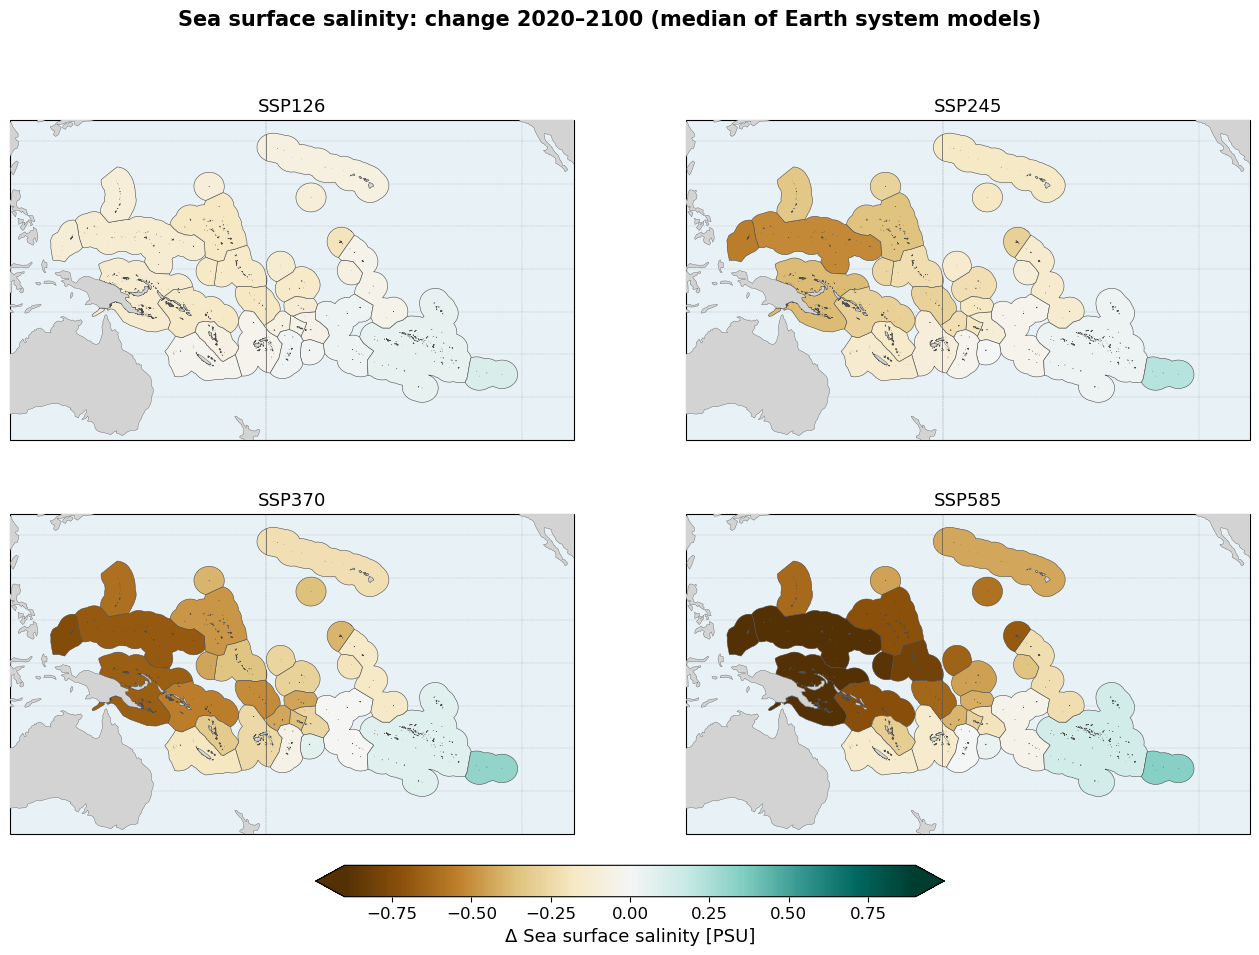

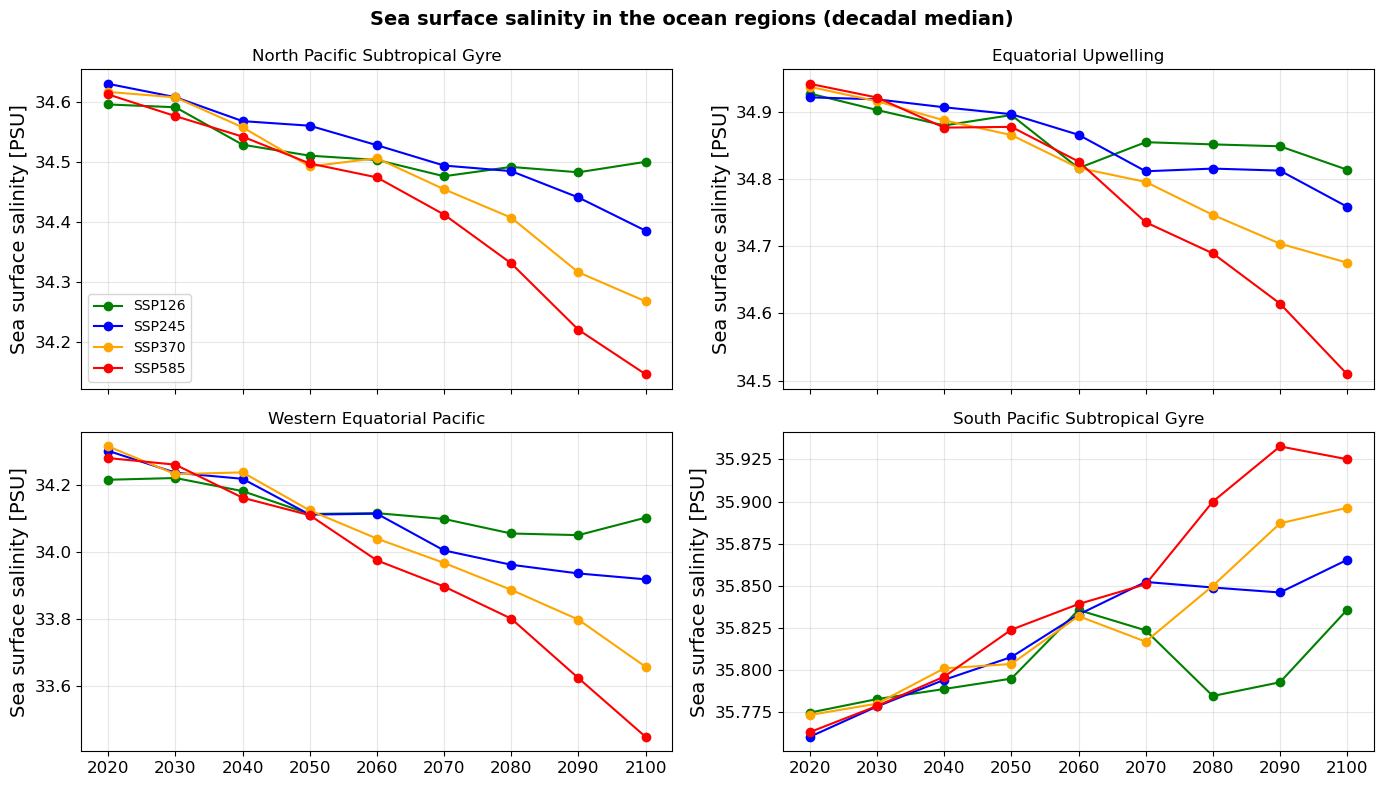

In [4]:
ds_ocads = reg.extract_ocads_regional("salinity", eez, ssp_scenarios)
figs, tables = reg.ocads_report(ds_ocads, "salinity", "Sea surface salinity", "PSU", eez, ssp_scenarios, fig_dir, tables_dir, cmap="BrBG")
glue("salinity_fig", figs["change"], display=False)
tables["regions"]